# Micromanage your agents — custom LangSmith dataset and evaluation

**Domain:** consumer-credit compliance QA for Cardinal Trust Bank
**Author:** Nnanyelugo Ahukannah

This notebook walks the pipeline end to end. The cheap, deterministic stages run
live here — corpus parsing, dataset construction and validation, the evaluator
controls, the target function on a couple of examples.

**The three LangSmith experiments are *not* re-run by this notebook.** They are
loaded from `experiment_results.json`, on purpose: re-running would add three more
experiments to the LangSmith project every time the notebook is executed, and
would silently change the numbers quoted in `evaluation_summary.md`. The
experiments are run once, by `run_evaluation.py`, and everything downstream reads
that artifact.

In [1]:
import collections, json, statistics, sys
from pathlib import Path

print("interpreter:", sys.executable)
assert "bootcamp-env" in sys.executable, "wrong kernel — expected bootcamp-env"

interpreter: /opt/homebrew/Caskroom/miniconda/base/envs/bootcamp-env/bin/python


## Step 2 — Environment

Keys come from the shared Ironhack store outside every git repo. They are never
printed; presence is verified by length and hash fingerprint. This workspace is in
the **EU** region, which needs `LANGSMITH_ENDPOINT` set — the default US endpoint
authenticates and then returns 403 on every call, which looks like a bad key.

In [2]:
import hashlib, os
from dotenv import load_dotenv

load_dotenv(Path.home() / ".config/ironhack/.env.local")
for name in ("OPENAI_API_KEY", "LANGSMITH_API_KEY"):
    v = os.getenv(name)
    assert v, f"{name} missing"
    print(f"{name:20} {len(v):>3} chars  sha256[:12]={hashlib.sha256(v.encode()).hexdigest()[:12]}")
print(f"{'LANGSMITH_ENDPOINT':20} {os.getenv('LANGSMITH_ENDPOINT')}")
print(f"{'LANGSMITH_PROJECT':20} {os.getenv('LANGSMITH_PROJECT')}")

OPENAI_API_KEY       167 chars  sha256[:12]=33010f935556
LANGSMITH_API_KEY     51 chars  sha256[:12]=5886a6c0816a
LANGSMITH_ENDPOINT   https://eu.api.smith.langchain.com
LANGSMITH_PROJECT    cardinal-trust-compliance-qa


## Step 1 & 3 — The corpus, and the clauses that anchor every answer

27 numbered clauses across three documents. The IDs are the join key: a dataset
example cites the clauses its reference answer comes from, and the build refuses
to emit an example whose citation does not resolve.

In [3]:
from corpus_index import load_clauses, corpus_as_context

clauses = load_clauses()
by_source = collections.defaultdict(list)
for c in clauses.values():
    by_source[c["source"]].append(c["id"])
for src, ids in by_source.items():
    print(f"{src:38} {len(ids):>2}  {', '.join(ids)}")
print(f"\ntotal {len(clauses)} clauses; context block {len(corpus_as_context(clauses).split())} words")
print("\nexample clause:")
print(" ", clauses["RB-5"]["title"]); print(" ", clauses["RB-5"]["body"][:220], "...")

cardinal_trust_credit_policy.md         9  CT-1, CT-2, CT-3, CT-4, CT-5, CT-6, CT-7, CT-8, CT-9
fcra_615a_notices.md                    7  FC-1, FC-2, FC-3, FC-4, FC-5, FC-6, FC-7
reg_b_adverse_action.md                11  RB-1, RB-2, RB-3, RB-4, RB-5, RB-6, RB-7, RB-8, RB-9, RB-10, RB-11

total 27 clauses; context block 1351 words

example clause:
  Timing: counteroffers
  Where the creditor makes a counteroffer, it must notify the applicant within 30
days. If the applicant does not expressly accept or use the credit offered within
**90 days** of the counteroffer, the creditor must then se ...


## Step 3 — Build the dataset, and prove the validator rejects bad input

A dataset builder that never rejects anything is indistinguishable from one that
works. These are negative controls: each mutation should be caught, and named
against the right example.

In [4]:
from build_dataset import validate, build, summarise
import copy

questions = json.loads(Path("questions.json").read_text())
print("baseline problems:", validate(questions, clauses) or "none")

for name, mutate in [
    ("fabricated citation", lambda q: q[0].update(clause_ids=["RB-99"])),
    ("duplicate id",        lambda q: q[1].update(id=q[0]["id"])),
    ("empty answer",        lambda q: q[2].update(answer="")),
    ("duplicate question",  lambda q: q[3].update(question=q[0]["question"])),
]:
    bad = copy.deepcopy(questions); mutate(bad)
    probs = validate(bad, clauses)
    print(f"  {name:22} -> {probs[0] if probs else 'NOT CAUGHT'}")

baseline problems: none
  fabricated citation    -> Q01: cites RB-99, which is not in the corpus
  duplicate id           -> Q01: duplicate example id
  empty answer           -> Q03: empty or missing field 'answer'
  duplicate question     -> Q04: duplicate question text


In [5]:
examples = build(questions, clauses)
print(summarise(examples))
print("\none example as uploaded to LangSmith:")
print(json.dumps(examples[0], indent=2)[:700])

22 examples
  by category:   edge_case=4, fcra=5, internal_policy=4, regulation_b=9
  by difficulty: easy=7, medium=9, hard=6
  multi-clause:  4 examples cite more than one clause

one example as uploaded to LangSmith:
{
  "inputs": {
    "question": "We received a personal loan application on 3 March but it was missing proof of income, which arrived on 20 March. By when must Cardinal Trust notify the applicant of the decision?"
  },
  "outputs": {
    "answer": "Within 30 days of 20 March, because the 30-day clock runs from the date the application became complete, not from the date it was first received.",
    "clause_ids": [
      "RB-3"
    ]
  },
  "metadata": {
    "example_id": "Q01",
    "category": "regulation_b",
    "difficulty": "easy",
    "clause_ids": [
      "RB-3"
    ],
    "source_docs": [
      "reg_b_adverse_action.md"
    ],
    "n_clauses": 1
  }
}


## Step 5 — The target function

The system prompt hands over the whole corpus and demands citations. Tracing is
automatic: the OpenAI client is wrapped with `wrap_openai` and each target carries
`@traceable`, so every call lands in the LangSmith project with its inputs,
outputs, tokens and latency.

The `terse` variant is the same model with the grounding discipline removed. It is
the experiment that produced the headline finding.

In [6]:
from target_function import SYSTEM_PROMPT, TERSE_SYSTEM_PROMPT, TARGETS, target_mini

print("full prompt — the instructions the terse variant drops:\n")
print(SYSTEM_PROMPT[:SYSTEM_PROMPT.index("REFERENCE CLAUSES")])
print("-" * 70)
print("terse prompt:\n")
print(TERSE_SYSTEM_PROMPT[:TERSE_SYSTEM_PROMPT.index("[RB-1]")])

full prompt — the instructions the terse variant drops:

You answer questions for Cardinal Trust Bank's compliance team
about consumer adverse-action notices.

Answer ONLY from the reference clauses below. They are the authority for this
task, and they override anything you believe about the law from other sources.
If the clauses do not settle the question, say so plainly rather than filling the
gap from general knowledge.

Cite the clause IDs your answer rests on. Cite only IDs that appear below; never
invent one.

Answer in two or three sentences. Be direct and specific — give the actual number,
deadline or requirement rather than describing where to find it.


----------------------------------------------------------------------
terse prompt:

Answer the compliance question using these reference
clauses.

[CT-1] Scope
This policy covers unsecured personal loans, credit cards and overdraft lines
offered to consumers by Cardinal Trust Bank. Business credit is out of scope and
is gove

In [7]:
# Step 5 asks for a smoke test before running the full evaluation.
for ex in examples[:2]:
    out = target_mini({"question": ex["inputs"]["question"]})
    print("Q:", ex["inputs"]["question"][:100])
    print("  answer:", out["answer"][:180])
    print(f"  cited : {out['clause_ids']}  (reference {ex['outputs']['clause_ids']})"
          f"   cost ${out['cost_usd']:.6f}   error={out['error']}\n")

Q: We received a personal loan application on 3 March but it was missing proof of income, which arrived
  answer: Cardinal Trust must notify the applicant of the decision within 30 days after receiving the completed application, which is by 19 April.
  cited : ['RB-4', 'RB-3']  (reference ['RB-3'])   cost $0.000334   error=None



Q: An application is still incomplete after three weeks. What are our options, and what must a notice o
  answer: If an application is incomplete after three weeks, we must either send a notice of incompleteness specifying the information needed and a reasonable period to provide it, or send a
  cited : ['RB-4']  (reference ['RB-4'])   cost $0.000351   error=None



## Steps 6 & 11 — The evaluators, and their controls

Five evaluators: one stock judge, one custom judge, three deterministic checks.
The deterministic ones are asserted against constructed inputs. Two cases exist
specifically because the first version of these evaluators got them wrong —
`prefix dropped` and `ambiguous number`.

In [8]:
from evaluators import (citation_validity, citation_wellformed,
                        citation_fabricated_free, ALL_EVALUATORS)

print("evaluators in use:", [e.__name__ for e in ALL_EVALUATORS], "\n")
rows = [
    ("exact match",      ["RB-3"],         ["RB-3"]),
    ("extra valid",      ["RB-3", "RB-4"], ["RB-3"]),
    ("missing one",      ["RB-3"],         ["RB-3", "CT-8"]),
    ("prefix dropped",   ["10"],           ["RB-10"]),
    ("ambiguous number", ["6"],            ["FC-6"]),
    ("fabricated",       ["RB-99"],        ["RB-3"]),
]
print(f"{'case':18}{'validity':>10}{'wellformed':>12}{'fabricated-free':>17}")
for name, cited, expected in rows:
    o, r = {"clause_ids": cited}, {"clause_ids": expected}
    print(f"{name:18}{citation_validity({}, o, r)['score']:>10}"
          f"{citation_wellformed({}, o, r)['score']:>12}"
          f"{citation_fabricated_free({}, o, r)['score']:>17}")

evaluators in use: ['correctness', 'citation_validity', 'citation_wellformed', 'citation_fabricated_free', 'groundedness'] 

case                validity  wellformed  fabricated-free
exact match              1.0         1.0              1.0
extra valid              1.0         1.0              1.0
missing one              0.0         1.0              1.0
prefix dropped           1.0         1.0              1.0
ambiguous number         0.0         0.0              1.0
fabricated               0.0         0.0              0.0


Note the third and fourth columns on `prefix dropped`: nothing was fabricated, but
the citation is only usable because `10` happens to be unambiguous. `6` is not —
`RB-6`, `FC-6` and `CT-6` all exist, so an auditor cannot tell which was meant.

Collapsing these into a single metric is what produced a false "77% hallucination"
reading on the `terse` run in the first version of this lab.

## Steps 7–9 — Results

Loaded from `experiment_results.json`, written by `run_evaluation.py`.

In [9]:
data = json.loads(Path("experiment_results.json").read_text())
analysis = json.loads(Path("analysis_summary.json").read_text())

print(f"dataset {data['dataset_name']}  ({data['dataset_id']})")
print(f"project {data['project']}   endpoint {data['endpoint']}\n")
for e in data["experiments"]:
    print(f"  {e['target']:6} {e['label']:32} {e['experiment_name']}")

dataset cardinal-trust-adverse-action-qa  (9f32b481-0b9d-4199-8cc9-25a4bb7a35c0)
project cardinal-trust-compliance-qa   endpoint https://eu.api.smith.langchain.com

  mini   gpt-4o-mini + grounded prompt    cardinal-mini-43432275
  gpt4o  gpt-4o + grounded prompt         cardinal-gpt4o-55d81686
  terse  gpt-4o-mini + terse prompt       cardinal-terse-86b10069


In [10]:
KEYS = ["correctness", "citation_validity", "citation_wellformed",
        "citation_fabricated_free", "groundedness"]
print(f"{'target':7}{'model':13}{'prompt':8}" + "".join(f"{k[:12]:>14}" for k in KEYS))
for h in analysis["headline"]:
    print(f"{h['target']:7}{h['model']:13}{h['prompt_variant']:8}"
          + "".join(f"{h['scores'][k]:>14.3f}" for k in KEYS))

print(f"\n{'target':7}{'$/1k':>10}{'$/mo @20k':>12}{'latency':>10}{'errors':>8}")
for h in analysis["headline"]:
    print(f"{h['target']:7}{h['cost_per_1k_queries']:>10.4f}{h['monthly_cost_usd']:>12.2f}"
          f"{h['latency_mean_s']:>9.2f}s{h['errors']:>8}")

target model        prompt     correctness  citation_val  citation_wel  citation_fab  groundedness
mini   gpt-4o-mini  full             0.818         0.909         1.000         1.000         0.955
gpt4o  gpt-4o       full             0.955         0.955         1.000         1.000         0.955
terse  gpt-4o-mini  terse            0.909         0.318         0.364         1.000         0.318

target       $/1k   $/mo @20k   latency  errors
mini       0.3359        6.72     1.42s       0
gpt4o      5.6073      112.15     1.13s       0
terse      0.3216        6.43     1.38s       0


`terse` scores **higher than `mini` on correctness** and collapses on everything
that checks whether the answer rests on anything. That gap is the finding: the
obvious metric ranked the broken configuration second-best.

In [11]:
print("FAILURE MODES")
for t, e in analysis["errors"].items():
    print(f"\n  {t}")
    for mode, n in sorted(e["counts"].items(), key=lambda kv: -kv[1]):
        print(f"    {mode:26} {n:>3}/22   {', '.join(e['examples'][mode][:8])}")

FAILURE MODES

  mini
    incorrect_answer             4/22   Q02, Q05, Q06, Q22
    wrong_or_missing_clause      2/22   Q09, Q20
    ungrounded_claim             1/22   Q22

  gpt4o
    wrong_or_missing_clause      1/22   Q20
    incorrect_answer             1/22   Q05
    ungrounded_claim             1/22   Q21

  terse
    wrong_or_missing_clause     15/22   Q03, Q04, Q05, Q06, Q10, Q11, Q12, Q15
    ungrounded_claim            15/22   Q03, Q04, Q05, Q06, Q10, Q11, Q12, Q15
    unverifiable_citation       14/22   Q03, Q04, Q05, Q06, Q10, Q11, Q12, Q15
    incorrect_answer             2/22   Q02, Q22


In [12]:
print("BY DIFFICULTY (correctness)")
for t, d in analysis["by_difficulty"].items():
    print(f"  {t:7} " + "  ".join(f"{k}={v['correctness']:.2f}(n={v['n']})"
          for k, v in sorted(d.items(), key=lambda kv: 'emh'.index(kv[0][0]))))
print("\nBY CATEGORY (correctness)")
for t, d in analysis["by_category"].items():
    print(f"  {t:7} " + "  ".join(f"{k}={v['correctness']:.2f}" for k, v in d.items()))

BY DIFFICULTY (correctness)
  mini    easy=0.86(n=7)  medium=0.67(n=9)  hard=1.00(n=6)
  gpt4o   easy=1.00(n=7)  medium=0.89(n=9)  hard=1.00(n=6)
  terse   easy=0.86(n=7)  medium=0.89(n=9)  hard=1.00(n=6)

BY CATEGORY (correctness)
  mini    edge_case=0.75  fcra=1.00  internal_policy=1.00  regulation_b=0.67
  gpt4o   edge_case=1.00  fcra=1.00  internal_policy=1.00  regulation_b=0.89
  terse   edge_case=0.75  fcra=1.00  internal_policy=1.00  regulation_b=0.89


## Auditing the judge

`openevals` instructs its judges to end their reasoning with "Thus, the score
should be: X". That sentence can be parsed and compared against the score actually
recorded — so a judge disagreeing with itself is measurable, for free, on every
run.

This is not decorative. My first `groundedness` prompt contradicted itself on
7.8% of judgements (5 of 64), always scoring false while reasoning true, and it
was producing a groundedness score of 0.409 on answers that were fine. The stock
correctness prompt was self-consistent on all 65 over the same run, so the
harness was not at fault. Rewriting the prompt in the stock rubric style fixed it.

In [13]:
for k, t in analysis["judge_audit"].items():
    rate = f"{t['mismatch_rate']:.1%}" if t["mismatch_rate"] is not None else "n/a"
    print(f"  {k:14} {t['judgements']:>3} judgements, {t['parseable']:>3} parseable, "
          f"{t['mismatches']:>2} self-contradictions ({rate})")
print("\n(before the prompt rewrite: groundedness 5/64 = 7.8%)")

  correctness     66 judgements,  65 parseable,  0 self-contradictions (0.0%)
  groundedness    66 judgements,  65 parseable,  0 self-contradictions (0.0%)

(before the prompt rewrite: groundedness 5/64 = 7.8%)


## Step 11 — Figures

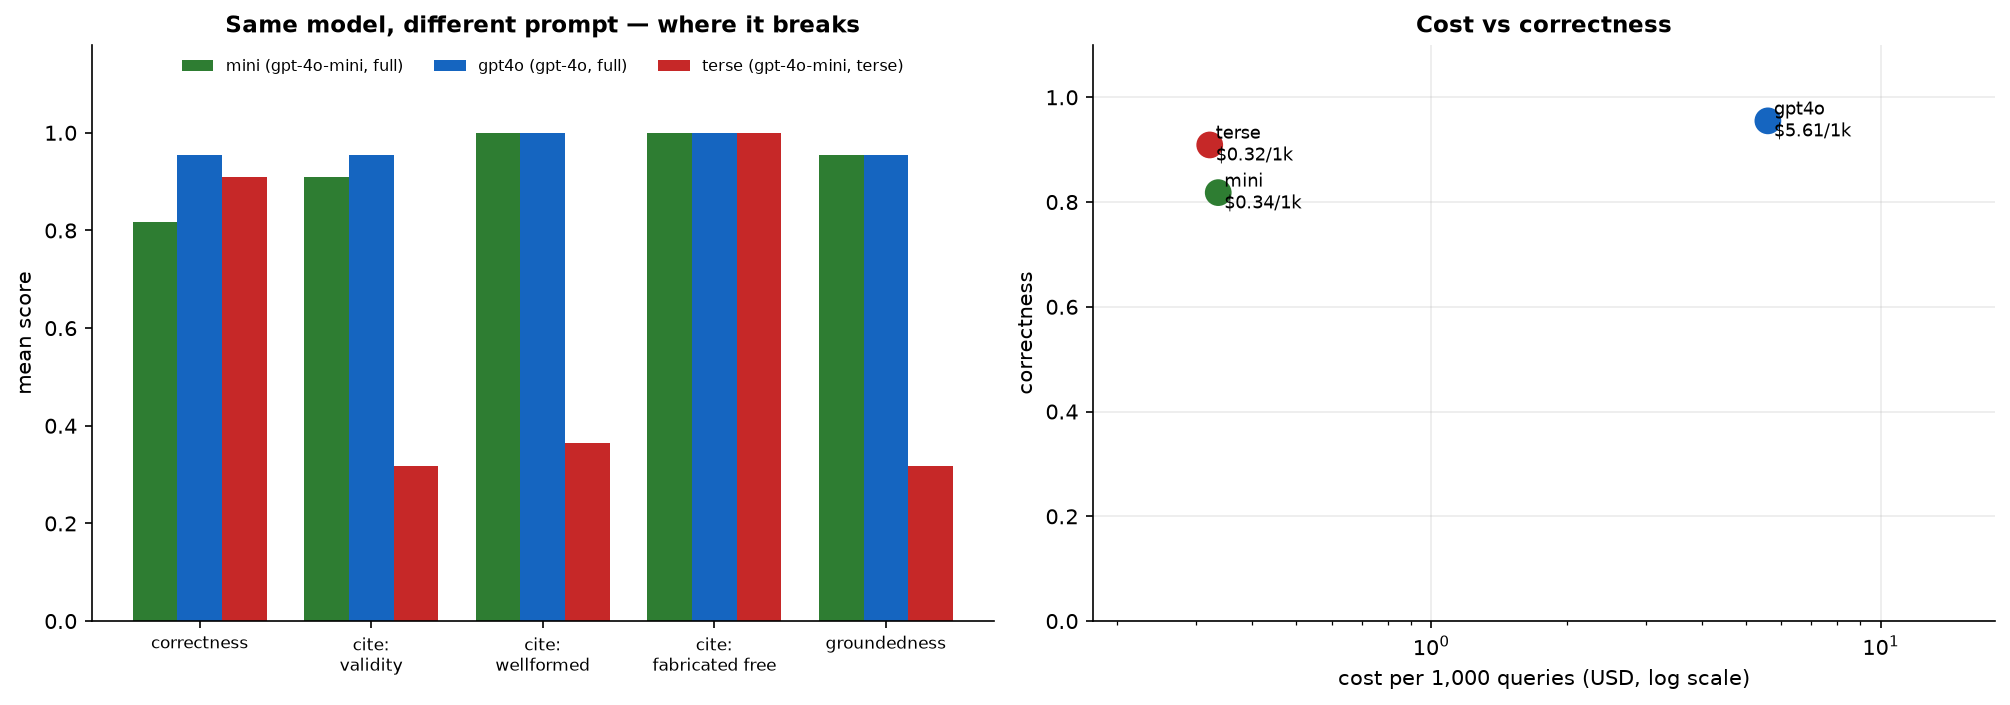

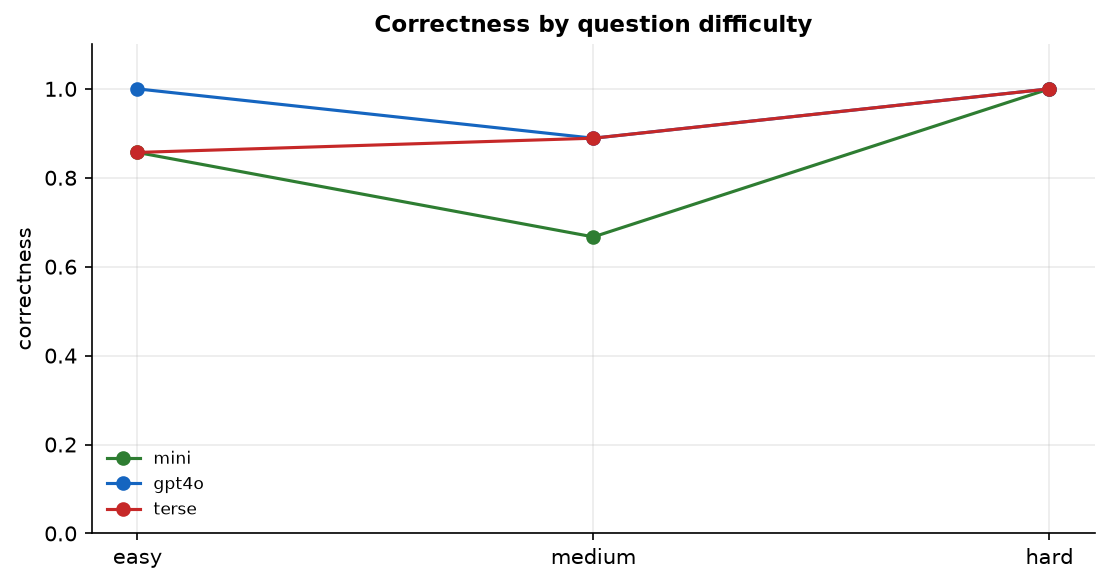

In [14]:
%matplotlib inline
from IPython.display import Image, display
for f in ("figures/experiment_comparison.png", "figures/difficulty_breakdown.png"):
    display(Image(filename=f))

## Step 8 — LangSmith UI

Captured from the EU workspace: the dataset with all six experiment runs, and the
three-way comparison view showing feedback scores, latency, token counts and cost
side by side.

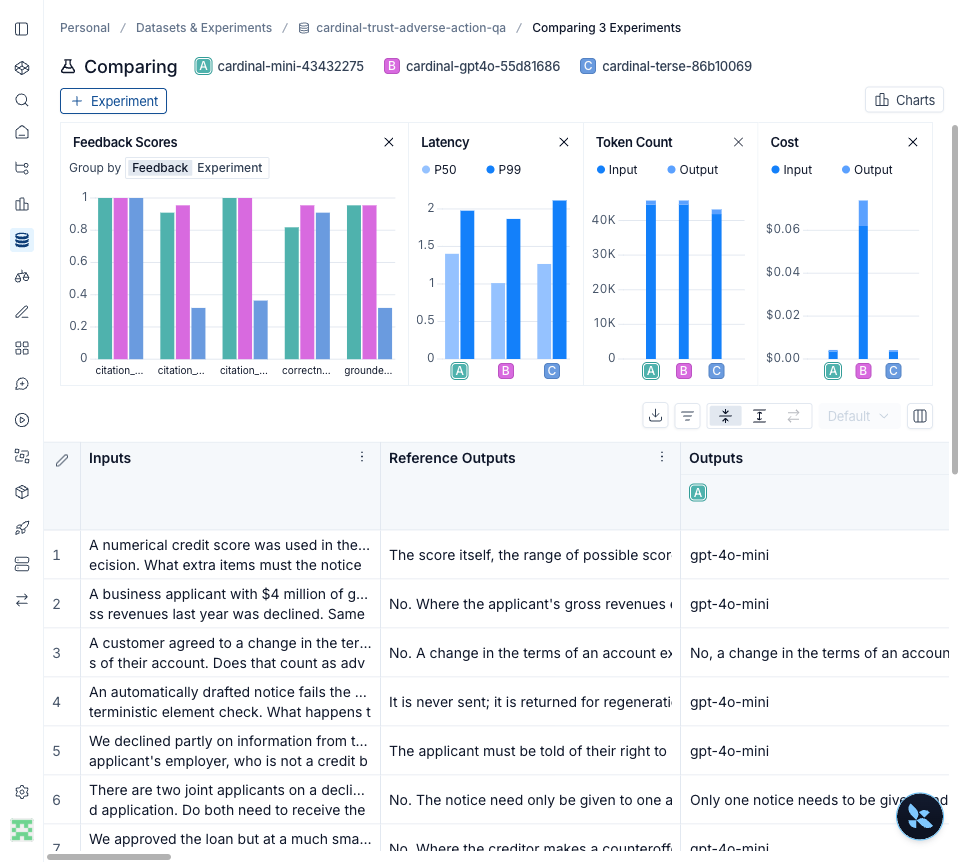

In [15]:
display(Image(filename="screenshots/langsmith_experiment_comparison.png"))

## What this run established

1. **Correctness was blind to the biggest failure.** Removing the grounding
   discipline from the prompt raised correctness (0.818 → 0.909) while collapsing
   citation validity (0.909 → 0.318) and groundedness (0.955 → 0.318). Same model.

2. **Nothing was fabricated, anywhere.** Zero invented clause references across
   all three runs. The 77% "hallucination" the first evaluator reported was a
   formatting failure — `6` instead of `FC-6` — and splitting the metric into
   *fabricated* / *well-formed* / *valid* is what corrected it.

3. **The custom judge needed auditing more than the models did.** 7.8%
   self-contradiction, fixed by rewriting the prompt in the stock rubric style,
   re-measured every run.

4. **The cheap lever was the prompt, not the model.** `gpt-4o` buys +0.137
   correctness for 16.7× the cost; prompt wording alone swings citation validity
   by 0.591 on the same model.

Recommendation, in `optimization_summary.md`: `gpt-4o-mini` with the full grounded
prompt, gated on citation validity rather than correctness.